# Explainable Machine Learning for Detecting Abnormal Used-Vehicle Prices

This notebook follows the research workflow: data loading, inspection, cleaning and preparation, feature engineering, expected-price modelling, abnormality detection, explainability and evaluation.


## 1. Environment Setup

In [1]:
import ast
import os
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 100)


## 2. Data Loading

In [2]:
DATASET1_PATH = "/content/vehicles.csv"
DATASET2_PATH = "/content/car_price_dataset.csv"

df1_raw = pd.read_csv(DATASET1_PATH)
df2_raw = pd.read_csv(DATASET2_PATH)

print("Dataset 1 shape:", df1_raw.shape)
print("Dataset 2 shape:", df2_raw.shape)


Dataset 1 shape: (258888, 26)
Dataset 2 shape: (9788, 17)


## 3. Initial Data Inspection

### 3.1 Dataset 1

In [3]:
print("Dataset 1 columns")
print(df1_raw.columns.tolist())
display(df1_raw.head())

print("Dataset 2 columns")
print(df2_raw.columns.tolist())
display(df2_raw.head())


Dataset 1 columns
['ad_title', 'ad_description', 'details', 'slug', 'title', 'type', 'price', 'timestamp', 'posted_date', 'deactivation_date', 'category', 'parent_category', 'location', 'geo_region', 'area', 'is_delivery_free', 'is_doorstep_delivery', 'is_dsd_applicable', 'is_member', 'is_authorized_dealer', 'is_featured_member', 'is_verified', 'membership_level', 'member_since', 'properties', 'user']


,ad_title,ad_description,details,slug,title,type,price,timestamp,posted_date,deactivation_date,category,parent_category,location,geo_region,area,is_delivery_free,is_doorstep_delivery,is_dsd_applicable,is_member,is_authorized_dealer,is_featured_member,is_verified,membership_level,member_since,properties,user
0,Nissan Tiida Alternator in Maharagama | ikman,**TISSA AUTO PARTS** Dealer of used Japanese motor spare parts and accessories. The best store t...,NaN,nissan-tiida-alternator-for-sale-colombo-3,Nissan Tiida Alternator,for_sale,"Rs 18,000",23 Feb 11:35 pm,2023-02-23T23:35:10+05:30,2022-05-30T17:13:04.000Z,Auto Parts & Accessories,Vehicles,Maharagama,LK-11,"{'id': 1506, 'name': 'Colombo'}",False,False,False,True,False,False,True,premium,September 2019,"{'Condition': 'Reconditioned', 'Part or Accessory Type': 'Electrical Components'}",a6681dea494390daa516a6d2bdcb36e08c318574a13413ccddb72ddfb90717de
1,Axio 165 Tail Light in Kotte | ikman,Imported from Japan \n\nRight side available \n\nContact us for all your spare part requirements.,NaN,axio-165-tail-light-for-sale-colombo-14,Axio 165 Tail Light,for_sale,"Rs 67,000",23 Feb 8:32 am,2023-02-23T08:32:44+05:30,2022-03-31T16:27:59.000Z,Auto Parts & Accessories,Vehicles,Kotte,LK-11,"{'id': 1506, 'name': 'Colombo'}",False,False,False,True,False,False,True,plus,June 2018,"{'Condition': 'Reconditioned', 'Part or Accessory Type': 'Lighting & Indicators', 'Brand': 'Othe...",5d99b8e45a1bb318079da7a36392d9025e1644cb49ecbf6ecc936042cd046fdf
2,Axio 165 / 161 Head light in Kotte | ikman.lk,Imported from Japan \n\nAuto focus headlight available both sides.\n\nContact us for all your sp...,NaN,axio-165-161-head-light-for-sale-colombo,Axio 165 / 161 Head light,for_sale,"Rs 85,000",01 Dec 8:27 pm,2022-12-01T20:27:49+05:30,2022-03-31T14:03:57.000Z,Auto Parts & Accessories,Vehicles,Kotte,LK-11,"{'id': 1506, 'name': 'Colombo'}",False,False,False,True,False,False,True,plus,June 2018,"{'Condition': 'Reconditioned', 'Part or Accessory Type': 'Lighting & Indicators'}",5d99b8e45a1bb318079da7a36392d9025e1644cb49ecbf6ecc936042cd046fdf
3,Vigo side step ( Foot board) in Kottawa | ikman,Hilux Vigo side step\nBrand New Thaiwan\nGood condition,NaN,vigo-side-step-foot-board-for-sale-colombo,Vigo side step ( Foot board),for_sale,"Rs 47,000",04 Dec 2:47 pm,2022-12-04T14:47:27+05:30,2022-07-29T13:22:59.000Z,Auto Parts & Accessories,Vehicles,Kottawa,LK-11,"{'id': 1506, 'name': 'Colombo'}",False,False,False,True,False,False,False,plus,February 2017,"{'Condition': 'New', 'Part or Accessory Type': 'Body Components'}",634d93e14a62d9de7b400ee3679ae1d5506f4252ff0580b073be9d2692dcac36
4,Vigo Dickey Door Garnish Cover in Kottawa | ikman,"Hilux Vigo ( 2005, 2009 ) dickey door garnish set",NaN,vigo-dickey-door-garnish-cover-for-sale-colombo-1,Vigo Dickey Door Garnish Cover,for_sale,"Rs 9,000",08 Dec 9:28 am,2022-12-08T09:28:04+05:30,2022-07-29T12:55:44.000Z,Auto Parts & Accessories,Vehicles,Kottawa,LK-11,"{'id': 1506, 'name': 'Colombo'}",False,False,False,True,False,False,False,plus,February 2017,"{'Condition': 'New', 'Part or Accessory Type': 'Body Components'}",634d93e14a62d9de7b400ee3679ae1d5506f4252ff0580b073be9d2692dcac36


Dataset 2 columns
['Unnamed: 0', 'Brand', 'Model', 'YOM', 'Engine (cc)', 'Gear', 'Fuel Type', 'Millage(KM)', 'Town', 'Date', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW', 'Price']


,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
0,0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,No Leasing,USED,Available,Available,Available,Available,100.0
1,1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,No Leasing,USED,Available,Available,Available,Available,97.0
2,2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,No Leasing,USED,Available,Available,Available,Available,98.5
3,3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,107.0
4,4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,No Leasing,USED,Available,Available,Available,Available,99.5


In [4]:
print("Advertisement categories")
print(df1_raw["category"].value_counts(dropna=False).head(30))

print("\nParent categories")
print(df1_raw["parent_category"].value_counts(dropna=False))


Advertisement categories
category
Motorbikes                  67642
Auto Parts & Accessories    67514
Cars                        48293
Three Wheelers              18117
Lorries & Trucks            12021
Auto Services               11625
Bicycles                    11315
Vans                         9486
Rentals                      7559
Tractors                     2450
Heavy Duty                   1862
Buses                         721
Boats & Water Transport       283
Name: count, dtype: int64

Parent categories
parent_category
Vehicles    258888
Name: count, dtype: int64


In [5]:
def get_properties(value):
    if isinstance(value, dict):
        return value
    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            if isinstance(parsed, dict):
                return parsed
        except (ValueError, SyntaxError):
            pass
    return {}

property_keys = Counter()

for value in df1_raw["properties"].dropna():
    property_keys.update(get_properties(value).keys())

print("Common property fields")
print(property_keys.most_common(30))


Common property fields
[('Condition', 238742), ('Brand', 191041), ('Model', 159795), ('Mileage', 155505), ('Engine capacity', 137510), ('Trim / Edition', 120384), ('Year of Manufacture', 115386), ('Part or Accessory Type', 67380), ('Bike Type', 67296), ('Transmission', 48090), ('Fuel type', 48090), ('Body type', 43911), ('Model year', 40119), ('Service type', 18989), ('Vehicle Type', 1858)]


### 3.2 Dataset 2

In [6]:
print("Dataset 2 columns")
print(df2_raw.columns.tolist())

print("\nData types")
print(df2_raw.dtypes)

print("\nPrice summary")
print(df2_raw["Price"].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99]))

print("\nListing date range")
print("Earliest:", df2_raw["Date"].min())
print("Latest:  ", df2_raw["Date"].max())

display(df2_raw.sample(min(10, len(df2_raw)), random_state=42))


Dataset 2 columns
['Unnamed: 0', 'Brand', 'Model', 'YOM', 'Engine (cc)', 'Gear', 'Fuel Type', 'Millage(KM)', 'Town', 'Date', 'Leasing', 'Condition', 'AIR CONDITION', 'POWER STEERING', 'POWER MIRROR', 'POWER WINDOW', 'Price']

Data types
Unnamed: 0          int64
Brand              object
Model              object
YOM                 int64
Engine (cc)       float64
Gear               object
Fuel Type          object
Millage(KM)       float64
Town               object
Date               object
Leasing            object
Condition          object
AIR CONDITION      object
POWER STEERING     object
POWER MIRROR       object
POWER WINDOW       object
Price             float64
dtype: object

Price summary
count    9788.000000
mean       53.464275
std        43.625049
min         2.650000
1%          6.243500
25%        26.250000
50%        43.000000
75%        69.750000
99%       225.000000
max       790.000000
Name: Price, dtype: float64

Listing date range
Earliest: 2024-12-03
Latest:   202

,Unnamed: 0,Brand,Model,YOM,Engine (cc),Gear,Fuel Type,Millage(KM),Town,Date,Leasing,Condition,AIR CONDITION,POWER STEERING,POWER MIRROR,POWER WINDOW,Price
9597,9598,TOYOTA,VITZ KSP90,2005,1000.0,Automatic,Petrol,220000.0,Ampara,2024-12-26,No Leasing,USED,Available,Available,Available,Available,55.000000
7135,7135,TOYOTA,AQUA G GRADE,2013,1499.0,Automatic,Petrol,132000.0,Homagama,2024-12-24,No Leasing,USED,Available,Available,Available,Available,78.750000
4708,4708,SUZUKI,ALTO K10,2011,1000.0,Manual,Petrol,154000.0,Ratnapura,2025-02-01,No Leasing,USED,Available,Available,Not_Available,Available,27.800000
6202,6202,SUZUKI,WAGON R STINGRAY,2018,660.0,Automatic,Hybrid,77000.0,Nugegoda,2025-02-03,No Leasing,USED,Available,Available,Available,Available,75.900000
8860,8861,TOYOTA,PRIUS,2013,1800.0,Automatic,Hybrid,132000.0,Wennappuwa,2024-12-05,No Leasing,USED,Available,Available,Available,Available,97.000000
4867,4867,SUZUKI,CELERIO,2015,996.0,Manual,Petrol,110000.0,Kaduwela,2025-01-21,No Leasing,USED,Available,Available,Not_Available,Available,40.000000
39,39,AUDI,A4 S LINE,2010,1800.0,Automatic,Petrol,165000.0,Galle,2025-01-10,No Leasing,USED,Available,Available,Available,Available,102.000000
7103,7103,TOYOTA,AQUA G GRADE,2013,1500.0,Automatic,Hybrid,132000.0,Gampaha,2025-02-04,No Leasing,USED,Available,Available,Available,Available,75.611538
7216,7216,TOYOTA,AQUA X URBAN,2015,1500.0,Automatic,Hybrid,110000.0,Colombo,2025-02-01,No Leasing,USED,Available,Available,Available,Available,86.000000
4702,4702,SUZUKI,ALTO K10,2015,1000.0,Manual,Petrol,110000.0,Matale,2025-02-03,No Leasing,USED,Available,Available,Not_Available,Available,38.613636


In [7]:
print("Lowest prices in Dataset 2")
display(
    df2_raw.sort_values("Price")[
        ["Brand", "Model", "YOM", "Engine (cc)", "Millage(KM)", "Date", "Price"]
    ].head(15)
)

print("Highest prices in Dataset 2")
display(
    df2_raw.sort_values("Price", ascending=False)[
        ["Brand", "Model", "YOM", "Engine (cc)", "Millage(KM)", "Date", "Price"]
    ].head(15)
)

print("Exact duplicate rows:", df2_raw.duplicated().sum())


Lowest prices in Dataset 2


,Brand,Model,YOM,Engine (cc),Millage(KM),Date,Price
8401,TOYOTA,KE50,1980,1400.0,495000.0,2025-02-02,2.65
2103,MITSUBISHI,COLT,1979,1400.0,506000.0,2024-12-22,3.25
2131,MITSUBISHI,GALANT,1975,1500.0,550000.0,2024-12-24,3.40
2488,NISSAN,B310,1979,1400.0,506000.0,2025-01-31,3.65
2165,MITSUBISHI,LANCER,1983,1400.0,462000.0,2024-12-19,3.75
8415,TOYOTA,LADA RIVA,1986,1400.0,429000.0,2025-01-25,3.75
2338,MITSUBISHI,LANCER WAGON,1978,1400.0,517000.0,2024-12-07,3.88
1310,ISUZU,GEMINI,1988,1500.0,407000.0,2025-02-03,3.90
1621,MAZDA,MAZDA,1993,1320.0,352000.0,2024-12-19,4.00
2486,NISSAN,B31,1984,1190.0,451000.0,2024-12-30,4.00


Highest prices in Dataset 2


,Brand,Model,YOM,Engine (cc),Millage(KM),Date,Price
8417,TOYOTA,LEXUS 600HL,2011,600.0,154000.0,2025-01-18,790.0
138,BMW,740LE M SPORT,2016,2000.0,99000.0,2025-01-16,575.0
1776,MERCEDES-BENZ,S400 LONG WHEEL BASE,2015,3500.0,110000.0,2025-02-05,550.0
55,AUDI,Q4,2024,1500.0,11000.0,2025-01-12,475.0
133,BMW,530I M SPORT,2017,2200.0,88000.0,2024-12-07,460.0
109,BMW,430I GRAN COUPE,2017,2000.0,88000.0,2025-02-03,450.0
153,BMW,M SPORT,2018,2000.0,77000.0,2025-01-14,425.0
1733,MERCEDES-BENZ,E200,2016,2000.0,99000.0,2024-12-05,405.0
159,BYD,SEAL,2024,1500.0,11000.0,2025-02-05,394.5
148,BMW,G30 530I,2017,2000.0,88000.0,2025-01-30,380.0


Exact duplicate rows: 0


## 4. Data Cleaning and Exploratory Data Analysis

### 4.1 Dataset 1

In [8]:
# Extract vehicle attributes and preserve the original listing indexes

df1_cars = df1_raw[
    df1_raw["category"].astype("string").str.strip().str.lower().eq("cars")
].copy()

properties_df = pd.json_normalize(
    df1_cars["properties"].apply(get_properties).tolist()
)
properties_df.index = df1_cars.index

def get_property(name):
    if name in properties_df.columns:
        return properties_df[name]
    return pd.Series(index=properties_df.index, dtype="object")

df1_clean = df1_cars.copy()

df1_clean["make"] = get_property("Brand")
df1_clean["model"] = get_property("Model")

year_manufactured = get_property("Year of Manufacture")
model_year = get_property("Model year")
df1_clean["year"] = year_manufactured.combine_first(model_year)

df1_clean["mileage"] = get_property("Mileage")
df1_clean["engine_capacity"] = get_property("Engine capacity")
df1_clean["transmission"] = get_property("Transmission")
df1_clean["fuel_type"] = get_property("Fuel type")
df1_clean["body_type"] = get_property("Body type")
df1_clean["condition"] = get_property("Condition")

print("Dataset 1 rows after category filter:", len(df1_clean))
display(
    df1_clean[
        ["ad_title", "price", "posted_date", "make", "model", "year",
         "mileage", "engine_capacity", "transmission", "fuel_type",
         "body_type", "condition"]
    ].head(10)
)


Dataset 1 rows after category filter: 48293


,ad_title,price,posted_date,make,model,year,mileage,engine_capacity,transmission,fuel_type,body_type,condition
31,Ssang Yong Rexton Ultimate d/ca 2019 in Nugegoda | ikman.lk,"Rs 22,000,000",2022-11-25T14:29:55+05:30,Ssang Yong,Rexton,2019,0 km,"2,200 cc",Tiptronic,Diesel,SUV / 4x4,New
1349,Toyota CHR 2017 in Kohuwala | ikman,"Rs 14,500,000",2023-01-12T09:26:22+05:30,Toyota,CHR,2017,"9,000 km","1,200 cc",Tiptronic,Petrol,CoupÃ©/Sports,Reconditioned
1701,Toyota Axio 2015 in Kohuwala | ikman,"Rs 10,500,000",2023-01-12T09:26:29+05:30,Toyota,Axio,2015,"24,000 km","1,500 cc",Automatic,Hybrid,Saloon,Reconditioned
1702,Daihatsu Atrai Wagon Turbo 2016 in Kohuwala | ikman.lk,"Rs 6,500,000",2022-11-09T14:33:53+05:30,Daihatsu,Atrai Wagon,2016,"55,000 km",650 cc,Automatic,Petrol,MPV,Reconditioned
1917,Mercedes Benz C180 2010 in Colombo 14 | ikman,"Rs 11,500,000",2022-12-14T16:17:03+05:30,Mercedes Benz,C180,2010,"137,000 km","1,595 cc",Tiptronic,Petrol,Saloon,Used
2042,BMW 520d Full Option 2013 in Dehiwala | ikman,"Rs 15,850,000",2023-01-12T09:26:16+05:30,BMW,520d,2013,"80,000 km","2,000 cc",Automatic,Diesel,NaN,Used
2513,Daihatsu Mira 2017 in Ja-Ela | ikman.lk,"Rs 6,150,000",2022-11-16T13:19:56+05:30,Daihatsu,Mira,2017,"7,800 km",660 cc,Automatic,Petrol,NaN,Reconditioned
3691,Mini Cooper Yellow 2004 in Nugegoda | ikman,"Rs 8,950,000",2023-01-22T21:14:48+05:30,Mini,Cooper,2004,"43,000 km","1,600 cc",Tiptronic,Petrol,Hatchback,Used
3694,Mercedes Benz C200 Silver C200d AMGLine 2018 in Nugegoda | ikman,"Rs 26,500,000",2023-01-22T21:14:51+05:30,Mercedes Benz,C200,2018,"34,000 km","1,600 cc",Tiptronic,Diesel,Saloon,Used
4061,Toyota Carina AT192 MYROAD 1500CC 1993 in Homagama | ikman,"Rs 2,275,000",2023-01-30T19:46:14+05:30,Toyota,Carina,1993,"210,000 km","1,490 cc",Manual,Petrol,Saloon,Used


In [9]:
def extract_number(series):
    values = (
        series.astype("string")
        .str.replace(",", "", regex=False)
        .str.extract(r"(-?\d+(?:\.\d+)?)", expand=False)
    )
    return pd.to_numeric(values, errors="coerce")

df1_clean["price_lkr"] = extract_number(df1_clean["price"])
df1_clean["year"] = extract_number(df1_clean["year"])
df1_clean["mileage_km"] = extract_number(df1_clean["mileage"])
df1_clean["engine_cc"] = extract_number(df1_clean["engine_capacity"])

df1_clean["listing_date"] = pd.to_datetime(
    df1_clean["posted_date"], errors="coerce", utc=True
)

print("Dataset 1 working copy shape:", df1_clean.shape)
display(
    df1_clean[
        ["ad_title", "price", "price_lkr", "year", "mileage",
         "mileage_km", "engine_capacity", "engine_cc", "listing_date"]
    ].head(10)
)

print("Missing values in selected fields")
print(
    df1_clean[
        ["price_lkr", "year", "mileage_km", "engine_cc", "listing_date",
         "make", "model"]
    ].isna().sum()
)


Dataset 1 working copy shape: (48293, 39)


,ad_title,price,price_lkr,year,mileage,mileage_km,engine_capacity,engine_cc,listing_date
31,Ssang Yong Rexton Ultimate d/ca 2019 in Nugegoda | ikman.lk,"Rs 22,000,000",22000000,2019,0 km,0,"2,200 cc",2200,2022-11-25 08:59:55+00:00
1349,Toyota CHR 2017 in Kohuwala | ikman,"Rs 14,500,000",14500000,2017,"9,000 km",9000,"1,200 cc",1200,2023-01-12 03:56:22+00:00
1701,Toyota Axio 2015 in Kohuwala | ikman,"Rs 10,500,000",10500000,2015,"24,000 km",24000,"1,500 cc",1500,2023-01-12 03:56:29+00:00
1702,Daihatsu Atrai Wagon Turbo 2016 in Kohuwala | ikman.lk,"Rs 6,500,000",6500000,2016,"55,000 km",55000,650 cc,650,2022-11-09 09:03:53+00:00
1917,Mercedes Benz C180 2010 in Colombo 14 | ikman,"Rs 11,500,000",11500000,2010,"137,000 km",137000,"1,595 cc",1595,2022-12-14 10:47:03+00:00
2042,BMW 520d Full Option 2013 in Dehiwala | ikman,"Rs 15,850,000",15850000,2013,"80,000 km",80000,"2,000 cc",2000,2023-01-12 03:56:16+00:00
2513,Daihatsu Mira 2017 in Ja-Ela | ikman.lk,"Rs 6,150,000",6150000,2017,"7,800 km",7800,660 cc,660,2022-11-16 07:49:56+00:00
3691,Mini Cooper Yellow 2004 in Nugegoda | ikman,"Rs 8,950,000",8950000,2004,"43,000 km",43000,"1,600 cc",1600,2023-01-22 15:44:48+00:00
3694,Mercedes Benz C200 Silver C200d AMGLine 2018 in Nugegoda | ikman,"Rs 26,500,000",26500000,2018,"34,000 km",34000,"1,600 cc",1600,2023-01-22 15:44:51+00:00
4061,Toyota Carina AT192 MYROAD 1500CC 1993 in Homagama | ikman,"Rs 2,275,000",2275000,1993,"210,000 km",210000,"1,490 cc",1490,2023-01-30 14:16:14+00:00


Missing values in selected fields
price_lkr       217
year            203
mileage_km      203
engine_cc       203
listing_date      0
make            203
model           203
dtype: int64


#### 4.1.1 Review incomplete vehicle details

In [10]:
print("Listings with missing make or model")

missing_vehicle_details = df1_clean[
    df1_clean["make"].isna() | df1_clean["model"].isna()
]

display(
    missing_vehicle_details[
        ["ad_title", "price", "make", "model", "year", "engine_capacity"]
    ].head(25)
)

print("Listings with possible accessory-related titles")

accessory_keywords = (
    r"\b(filter|spare parts|accessories|headlight|taillight|"
    r"bumper|mirror|tyre|tire|wheel rim|seat cover|car stereo|"
    r"wiper|radiator|gearbox|engine parts)\b"
)

possible_accessories = df1_clean[
    df1_clean["ad_title"].astype("string").str.contains(
        accessory_keywords, case=False, na=False, regex=True
    )
]

print("Possible accessory listings:", len(possible_accessories))

display(
    possible_accessories[
        ["ad_title", "price", "make", "model", "year"]
    ].head(40)
)

Listings with missing make or model


,ad_title,price,make,model,year,engine_capacity
12180,Looking for A Car in Rajagiriya | ikman.lk,NaN,NaN,NaN,<NA>,NaN
12631,Suzuki Wagon R Stingray 2018 Wanted in Colombo 10 | ikman.lk,NaN,NaN,NaN,<NA>,NaN
13500,à¶à·à· à¶¹ à¶´à·à·à·à¶§à· à¶à¶ºà¶­à¶±à¶ºà¶à¶§ à¶à·à¶»à· à¶»à¶® à¶ à·à·à·âà¶ºà¶ºà...,NaN,NaN,NaN,<NA>,NaN
14423,Want a Car in Nugegoda | ikman.lk,NaN,NaN,NaN,<NA>,NaN
14470,Toyota Premio Car in Angoda | ikman.lk,NaN,NaN,NaN,<NA>,NaN
19580,Want a car immediatly in Gampaha City | ikman.lk,NaN,NaN,NaN,<NA>,NaN
20777,Need a Car in Colombo 15 | ikman.lk,NaN,NaN,NaN,<NA>,NaN
25633,à·à·à¶±à· à¶»à¶®à¶ºà¶à· à¶à·à¶¸à¶±à·à¶ºà· in Trincomalee City | ikman.lk,NaN,NaN,NaN,<NA>,NaN
25841,Need Car in Anuradhapura City | ikman.lk,NaN,NaN,NaN,<NA>,NaN
29656,Need Toyota Axio 2015 in Matara City | ikman.lk,NaN,NaN,NaN,<NA>,NaN


Listings with possible accessory-related titles
Possible accessory listings: 1


/tmp/ipykernel_54616/2085076964.py:22: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df1_clean["ad_title"].astype("string").str.contains(


,ad_title,price,make,model,year
99195,Toyota Vitz WINKER MIRROR 8AIRBA 2007 in Colombo 6 | ikman,"Rs 4,160,000",Toyota,Vitz,2007


In [11]:
missing_details = df1_clean[
    df1_clean[["make", "model", "year"]].isna().any(axis=1)
]

display(
    missing_details[
        ["ad_title", "properties", "price", "posted_date"]
    ].head(20)
)

print("Records with missing vehicle details:", len(missing_details))

,ad_title,properties,price,posted_date
12180,Looking for A Car in Rajagiriya | ikman.lk,{},NaN,2022-10-28T01:23:06+05:30
12631,Suzuki Wagon R Stingray 2018 Wanted in Colombo 10 | ikman.lk,{},NaN,2022-10-28T12:07:16+05:30
13500,à¶à·à· à¶¹ à¶´à·à·à·à¶§à· à¶à¶ºà¶­à¶±à¶ºà¶à¶§ à¶à·à¶»à· à¶»à¶® à¶ à·à·à·âà¶ºà¶ºà...,{},NaN,2022-10-28T13:14:29+05:30
14423,Want a Car in Nugegoda | ikman.lk,{},NaN,2022-10-29T11:41:39+05:30
14470,Toyota Premio Car in Angoda | ikman.lk,{},NaN,2022-10-29T11:19:42+05:30
19580,Want a car immediatly in Gampaha City | ikman.lk,{},NaN,2022-10-31T12:45:29+05:30
20777,Need a Car in Colombo 15 | ikman.lk,{},NaN,2022-11-01T20:14:07+05:30
25633,à·à·à¶±à· à¶»à¶®à¶ºà¶à· à¶à·à¶¸à¶±à·à¶ºà· in Trincomalee City | ikman.lk,{},NaN,2022-11-04T16:24:43+05:30
25841,Need Car in Anuradhapura City | ikman.lk,{},NaN,2022-11-04T15:55:31+05:30
29656,Need Toyota Axio 2015 in Matara City | ikman.lk,{},NaN,2022-11-05T02:36:23+05:30


Records with missing vehicle details: 203


In [12]:
df1_clean = df1_clean.dropna(
    subset=["make", "model", "year"]
).copy()

print("Dataset 1 rows after removing incomplete listings:", len(df1_clean))
print("Remaining missing make:", df1_clean["make"].isna().sum())
print("Remaining missing model:", df1_clean["model"].isna().sum())
print("Remaining missing year:", df1_clean["year"].isna().sum())

Dataset 1 rows after removing incomplete listings: 48090
Remaining missing make: 0
Remaining missing model: 0
Remaining missing year: 0


#### 4.1.2 Review and exclude unclassified vehicle makes

In [13]:
# inspect listings classified as Other brand

display(
    df1_clean[
        df1_clean["make"].astype("string").str.strip().str.lower().eq("other brand")
    ][["ad_title", "model", "year", "engine_capacity", "price"]]
    .sort_values("ad_title")
)

,ad_title,model,year,engine_capacity,price
186747,1967 in Kohuwala | ikman,Other model,1967,"1,780 cc","Rs 2,500,000"
221170,2016 in Maharagama | ikman,Other model,2016,"2,400 cc","Rs 1,850,000"
135997,2016 in Moratuwa | ikman,Other model,2016,"1,000 cc","Rs 4,400,000"
51980,Ambassador ClasicCar 2004 in Galle City | ikman.lk,Other model,2004,"2,000 cc","Rs 1,675,000"
118248,Ambassador Grand 2006 in Ragama | ikman,Other model,2006,"1,995 cc","Rs 2,040,000"
...,...,...,...,...,...
77258,Willys Wrangler Jeep 1980 in Nittambuwa | ikman.lk,Other model,1980,"2,659 cc","Rs 2,850,000"
217030,Wuling Almaz SUV 2022 in Homagama | ikman,Other model,2022,"1,500 cc","Rs 15,900,000"
16632,bajaj qute 2019 in Digana | ikman.lk,Other model,2019,217 cc,"Rs 1,549,000"
181042,piagio India Truck 2012 in Gampola | ikman,Other model,2012,"3,000 cc","Rs 1,000,000"


In [14]:
# remove listings with unclassified vehicle makes

df1_clean = df1_clean[
    df1_clean["make"].notna() &
    df1_clean["make"].str.strip().ne("Other brand")
].copy()

print("Dataset 1 records after filtering:", len(df1_clean))
print("Remaining Other brand records:",
      df1_clean["make"].eq("Other brand").sum())

Dataset 1 records after filtering: 47979
Remaining Other brand records: 0


#### 4.1.3 Review and clean engine capacity

In [15]:
# inspect incompatible engine capacity records

engine_review = df1_clean[
    (df1_clean["engine_cc"] < 400) |
    (df1_clean["engine_cc"] > 6000)
]

engine_review[["ad_title", "make", "model", "engine_capacity", "engine_cc"]].head(30)


display(
    engine_review[
        ["make", "model", "ad_title", "engine_capacity", "engine_cc"]
    ].groupby(["make", "model"], dropna=False)
    .size()
    .reset_index(name="record_count")
    .sort_values("record_count", ascending=False)
    .head(20)
)

,make,model,record_count
40,Nissan,Leaf,200
3,Chevrolet,Other Model,19
43,Nissan,Sunny,11
0,BMW,i3,10
53,Suzuki,Maruti,5
49,Suzuki,Alto,5
58,Tata,Nano,5
65,Toyota,Hilux,4
35,Mitsubishi,Lancer,4
72,Toyota,Vitz,4


In [16]:
# set incompatible engine capacities to missing values

low_engine_mask = df1_clean["engine_cc"] < 400
high_engine_mask = df1_clean["engine_cc"] > 6000

print("Values below 400 cc:", low_engine_mask.sum())
print("Values above 6,000 cc:", high_engine_mask.sum())

df1_clean.loc[
    low_engine_mask | high_engine_mask,
    ["engine_cc", "engine_capacity"]
] = np.nan

print("\nRemaining values below 400 cc:",
      (df1_clean["engine_cc"] < 400).sum())

print("Remaining values above 6,000 cc:",
      (df1_clean["engine_cc"] > 6000).sum())

Values below 400 cc: 311
Values above 6,000 cc: 46

Remaining values below 400 cc: 0
Remaining values above 6,000 cc: 0


#### 4.1.4 Review and clean mileage

In [17]:
# inspect unusually high and invalid mileage values

print("Mileage summary:")
display(df1_clean["mileage_km"].describe().to_frame())

mileage_review = df1_clean[
    (df1_clean["mileage_km"] < 0) |
    (df1_clean["mileage_km"] > 400000)
]

print("\nMileage records requiring review:", len(mileage_review))

display(
    mileage_review[
        ["ad_title", "make", "model", "year", "mileage_km", "price_lkr"]
    ].sort_values("mileage_km", ascending=False).iloc[300:330]
)

Mileage summary:


,mileage_km
count,47979.0
mean,111174.366598
std,77788.216004
min,0.0
25%,60000.0
50%,98000.0
75%,146000.0
max,1000000.0



Mileage records requiring review: 321


,ad_title,make,model,year,mileage_km,price_lkr
191268,Morris Marina 1972 in Polgahawela | ikman,Morris,Other Model,1972,420000,465000
112154,Toyota corona RT81 1972 in Eheliyagoda | ikman,Toyota,Other Model,1972,420000,950000
250494,Nissan Dutsun TD 27 two wheel 1992 in Nugegoda | ikman,Nissan,Dutsun,1992,420000,3075000
76965,Peugeot 505 1972 in Matara City | ikman.lk,Peugeot,505,1972,420000,500000
202257,Toyota Corolla 1997 in Malabe | ikman,Toyota,Corolla,1997,419000,2690000
96427,Suzuki Alto 2015 in Nugegoda | ikman,Suzuki,Alto,2015,416000,3050000
83752,Mitsubishi L200 1996 in Dikwella | ikman.lk,Mitsubishi,L200,1996,414400,3200000
82672,Toyota Corona RT81 1973 in Gampaha City | ikman,Toyota,Corona,1973,411600,950000
53228,Land Rover SV Coupe 1973 in Kiribathgoda | ikman.lk,Land Rover,SV Coupe,1973,411600,700000
185453,Mitsubishi Lancer 1973 in Kurunegala City | ikman,Mitsubishi,Lancer,1973,411600,420000


In [18]:
# set extremely high mileage values to missing

high_mileage_mask = df1_clean["mileage_km"] > 600000
print("Mileage values to be set as missing:", high_mileage_mask.sum())

df1_clean.loc[high_mileage_mask, "mileage_km"] = np.nan

print("Remaining mileage values above 600,000 km:", (df1_clean["mileage_km"] > 600000).sum())
print("Total missing mileage values:", df1_clean["mileage_km"].isna().sum())

Mileage values to be set as missing: 96
Remaining mileage values above 600,000 km: 0
Total missing mileage values: 96


#### 4.1.5 Review and clean asking prices

In [19]:
# inspect missing and invalid vehicle prices

print("Missing prices:", df1_clean["price_lkr"].isna().sum())
print("Zero or negative prices:", (df1_clean["price_lkr"] <= 0).sum())

display(
    df1_clean.loc[
        df1_clean["price_lkr"].isna() | (df1_clean["price_lkr"] <= 0),
        ["ad_title", "make", "model", "year", "price", "price_lkr"]
    ].head(20)
)

Missing prices: 14
Zero or negative prices: 0


,ad_title,make,model,year,price,price_lkr
69645,Renault KWID 2016 in Homagama | ikman.lk,Renault,KWID,2016,Negotiable,<NA>
90438,Honda Vezel RS 2019 in Gampaha City | ikman,Honda,Vezel,2019,Negotiable,<NA>
169267,Toyota Premio ORIGINAL G SUPERIOR 2011 in Mount Lavinia | ikman,Toyota,Premio,2011,Negotiable,<NA>
185087,Toyota Axio X LIMITED PREMIUM 2011 in Mount Lavinia | ikman,Toyota,Axio,2011,Negotiable,<NA>
195767,Toyota Premio G SUPERIOR PREMIUM 2011 in Mount Lavinia | ikman,Toyota,Premio,2011,NaN,<NA>
202205,Audi A4 Premium 2016 in Dehiwala | ikman,Audi,A4,2016,Negotiable,<NA>
210542,"BMW 318i 10,000kms Luxury Lin 2020 in Dehiwala | ikman",BMW,318i,2020,Negotiable,<NA>
212863,Honda Accord 2019 in Kohuwala | ikman,Honda,Accord,2019,Negotiable,<NA>
216419,Toyota CHR 2018 in Kohuwala | ikman,Toyota,CHR,2018,Negotiable,<NA>
217007,"BMW 318i 10,000KM Luxury Line 2020 in Dehiwala | ikman",BMW,318i,2020,Negotiable,<NA>


In [20]:
# remove listings without a usable asking price

before_count = len(df1_clean)

df1_clean = df1_clean.dropna(subset=["price_lkr"]).copy()

print("Records removed:", before_count - len(df1_clean))
print("Remaining Dataset 1 records:", len(df1_clean))
print("Missing prices:", df1_clean["price_lkr"].isna().sum())

Records removed: 14
Remaining Dataset 1 records: 47965
Missing prices: 0


In [21]:
# inspect the cleaned asking-price distribution

display(df1_clean["price_lkr"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
))

display(
    df1_clean.nsmallest(10, "price_lkr")[
        ["ad_title", "make", "model", "year", "price_lkr"]
    ]
)

display(
    df1_clean.nlargest(10, "price_lkr")[
        ["ad_title", "make", "model", "year", "price_lkr"]
    ]
)

,price_lkr
count,47965.0
mean,7989193.653018
std,14517517.896216
min,1.0
1%,550000.0
5%,1075000.0
25%,2775000.0
50%,5100000.0
75%,8300000.0
95%,25750000.0


,ad_title,make,model,year,price_lkr
225215,BMW 740Le Msport 2018 LWB in Colombo 7 | ikman,BMW,740Le,2018,1
155477,Toyota Corolla 1996 in Chilaw | ikman,Toyota,Corolla,1996,2
19548,Kia Sportage HIGHEST SPEC 2011 in Kohuwala | ikman.lk,Kia,Sportage,2011,84
227612,Toyota Prius used 2011 in Veyangoda | ikman,Toyota,Prius,2011,1234
153485,Mahindra Bolero 2013 in Nugegoda | ikman,Mahindra,Bolero,2013,2150
90639,Land Rover Defender 2600cc 1957 in Matugama | ikman,Land Rover,Defender,1957,38500
194512,Toyota Carina 1986 in Batticaloa City | ikman,Toyota,Carina,1986,80000
35432,Mazda Familia 323 1986 in Chilaw | ikman.lk,Mazda,Familia,1986,97500
204653,Toyota Corolla 1989 in Homagama | ikman,Toyota,Corolla,1989,100500
76450,Toyota Corolla K20 1971 in Gampaha City | ikman.lk,Toyota,Corolla,1971,150000


,ad_title,make,model,year,price_lkr
97894,Mitsubishi Montero DID 2013 in Dehiwala | ikman,Mitsubishi,Montero,2013,1980000000
76096,Kia Sorento 2018 in Kalutara City | ikman.lk,Kia,Sorento,2018,1000000000
186842,Audi A5 S Line 2019 in Colombo 6 | ikman,Audi,A5,2019,249000000
252897,Audi A6 S Line 2017 in Colombo 7 | ikman,Audi,A6,2017,230000000
130464,BMW X2 2018 in Nugegoda | ikman,BMW,X2,2018,210000000
17487,Toyota Premio G Superior 2019 in Kohuwala | ikman.lk,Toyota,Premio,2019,162900000
119254,Land Rover Range Autobiography LWB 2019 in Colombo 4 | ikman,Land Rover,Range Rover,2019,147500000
106018,Land Rover Range unregistered LWB 2019 in Colombo 4 | ikman,Land Rover,Range Rover,2019,145000000
227526,Land Rover Range SV - LWB 2018 in Rajagiriya | ikman,Land Rover,Range Rover,2018,139000000
244095,Land Rover Range SV - LWB 2018 in Rajagiriya | ikman,Land Rover,Range Rover,2018,139000000


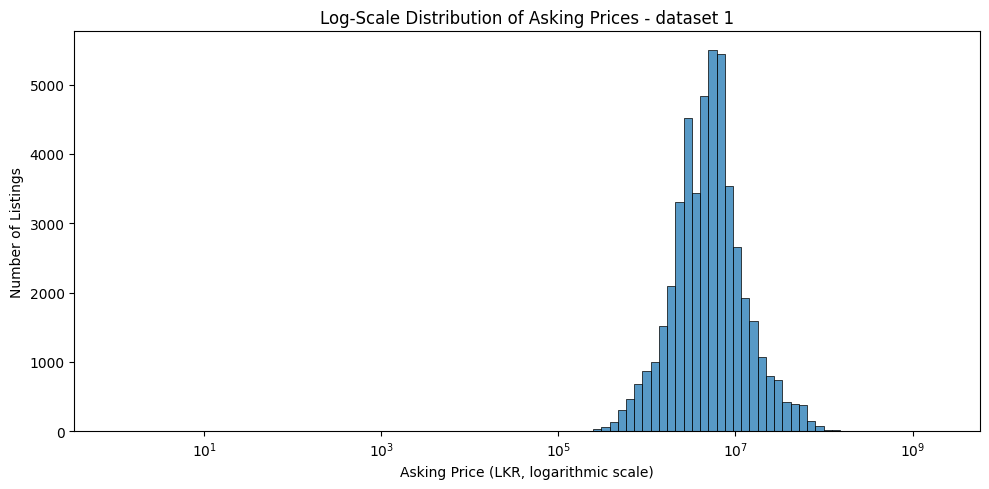

In [22]:
# visualize asking-price distribution using a logarithmic scale

plt.figure(figsize=(10, 5))

sns.histplot(
    df1_clean["price_lkr"],
    bins=100,
    log_scale=True
)

plt.title("Log-Scale Distribution of Asking Prices - dataset 1")
plt.xlabel("Asking Price (LKR, logarithmic scale)")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

In [23]:
# review unusually low and high asking prices

low_price_records = df1_clean[
    df1_clean["price_lkr"] <= 100000
]

high_price_records = df1_clean[
    df1_clean["price_lkr"] >= 150000000
]

print("Unusually low-price records:", len(low_price_records))
print("Unusually high-price records:", len(high_price_records))

print("\nLow-price records:")
display(
    low_price_records[
        ["ad_title", "make", "model", "year", "price_lkr"]
    ].sort_values("price_lkr")
)

print("\nHigh-price records:")
display(
    high_price_records[
        ["ad_title", "make", "model", "year", "price_lkr"]
    ].sort_values("price_lkr", ascending=False)
)

Unusually low-price records: 8
Unusually high-price records: 6

Low-price records:


,ad_title,make,model,year,price_lkr
225215,BMW 740Le Msport 2018 LWB in Colombo 7 | ikman,BMW,740Le,2018,1
155477,Toyota Corolla 1996 in Chilaw | ikman,Toyota,Corolla,1996,2
19548,Kia Sportage HIGHEST SPEC 2011 in Kohuwala | ikman.lk,Kia,Sportage,2011,84
227612,Toyota Prius used 2011 in Veyangoda | ikman,Toyota,Prius,2011,1234
153485,Mahindra Bolero 2013 in Nugegoda | ikman,Mahindra,Bolero,2013,2150
90639,Land Rover Defender 2600cc 1957 in Matugama | ikman,Land Rover,Defender,1957,38500
194512,Toyota Carina 1986 in Batticaloa City | ikman,Toyota,Carina,1986,80000
35432,Mazda Familia 323 1986 in Chilaw | ikman.lk,Mazda,Familia,1986,97500



High-price records:


,ad_title,make,model,year,price_lkr
97894,Mitsubishi Montero DID 2013 in Dehiwala | ikman,Mitsubishi,Montero,2013,1980000000
76096,Kia Sorento 2018 in Kalutara City | ikman.lk,Kia,Sorento,2018,1000000000
186842,Audi A5 S Line 2019 in Colombo 6 | ikman,Audi,A5,2019,249000000
252897,Audi A6 S Line 2017 in Colombo 7 | ikman,Audi,A6,2017,230000000
130464,BMW X2 2018 in Nugegoda | ikman,BMW,X2,2018,210000000
17487,Toyota Premio G Superior 2019 in Kohuwala | ikman.lk,Toyota,Premio,2019,162900000


In [24]:
# remove listings with clearly implausible asking prices

invalid_price_mask = (
    (df1_clean["price_lkr"] <= 2150) |
    (df1_clean["price_lkr"] >= 1000000000)
)

print("Records to remove:", invalid_price_mask.sum())

df1_clean = df1_clean.loc[~invalid_price_mask].copy()

print("Remaining Dataset 1 records:", len(df1_clean))
print("Missing prices:", df1_clean["price_lkr"].isna().sum())

Records to remove: 7
Remaining Dataset 1 records: 47958
Missing prices: 0


#### 4.1.6 Review and correct manufacturing years

In [25]:
# inspect future manufacturing years

future_years = df1_clean[
    df1_clean["year"] > df1_clean["listing_date"].dt.year
]

display(
    future_years[
        ["ad_title", "make", "model", "year", "listing_date"]
    ]
)

,ad_title,make,model,year,listing_date
71722,Mitsubishi Lancer 2023 in Kolonnawa | ikman.lk,Mitsubishi,Lancer,2023,2022-11-25 18:48:25+00:00
199508,Toyota Hilux 2004 2024 in Piliyandala | ikman,Toyota,Hilux,2024,2023-02-15 13:39:31+00:00
200230,Mitsubishi Lancer AB 2024 in Puttalam City | ikman,Mitsubishi,Lancer,2024,2023-02-16 04:08:53+00:00
219636,Daihatsu Charade 2024 in Bandaragama | ikman,Daihatsu,Charade,2024,2023-02-28 07:15:27+00:00


In [26]:
# set future manufacturing years to missing

future_year_mask = (
    df1_clean["year"] > df1_clean["listing_date"].dt.year
)

print("Future years to correct:", future_year_mask.sum())

df1_clean.loc[future_year_mask, "year"] = np.nan

print("Remaining future years:",
      (df1_clean["year"] > df1_clean["listing_date"].dt.year).sum())

print("Missing manufacturing years:", df1_clean["year"].isna().sum())

Future years to correct: 4
Remaining future years: 0
Missing manufacturing years: 4


#### 4.1.7 Validate cleaned numeric attributes

In [27]:
# validate cleaned numeric vehicle attributes

numeric_columns = [
    "year",
    "engine_cc",
    "mileage_km",
    "price_lkr"
]

display(df1_clean[numeric_columns].describe())

print("\nMissing values:")
display(df1_clean[numeric_columns].isna().sum())

print("\nInvalid values:")
print("Future manufacturing years:",
      (df1_clean["year"] > df1_clean["listing_date"].dt.year).sum())
print("Negative mileage:",
      (df1_clean["mileage_km"] < 0).sum())
print("Non-positive prices:",
      (df1_clean["price_lkr"] <= 0).sum())

,year,engine_cc,mileage_km,price_lkr
count,47954.0,47601.0,47862.0,47958.0
mean,2008.492931,1508.926619,109795.628453,7928221.987906
std,10.319679,670.746089,71136.711736,10448382.220014
min,1924.0,400.0,0.0,38500.0
25%,2004.0,1000.0,60000.0,2775000.0
50%,2012.0,1500.0,98000.0,5100000.0
75%,2016.0,1800.0,145000.0,8300000.0
max,2023.0,6000.0,600000.0,249000000.0



Missing values:


,0
year,4
engine_cc,357
mileage_km,96
price_lkr,0



Invalid values:
Future manufacturing years: 0
Negative mileage: 0
Non-positive prices: 0


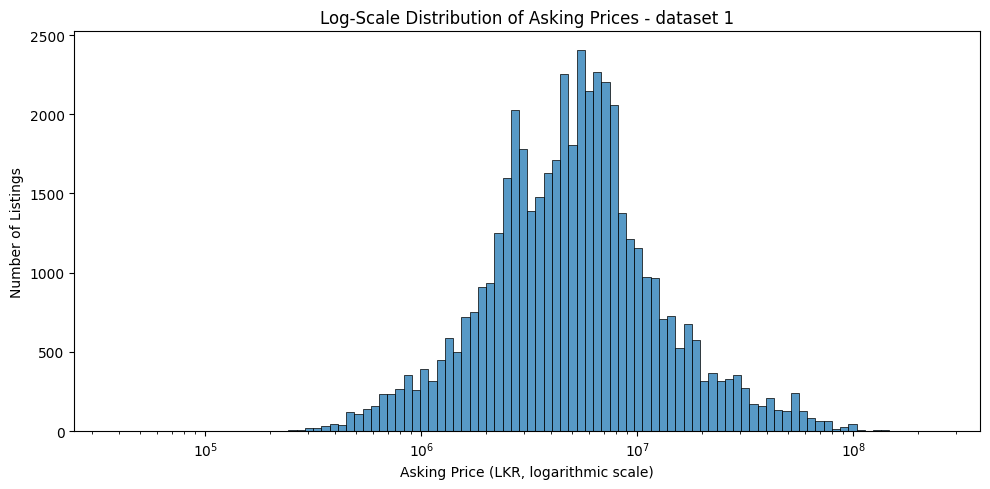

In [28]:
# visualize asking-price distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    df1_clean["price_lkr"],
    bins=100,
    log_scale=True
)

plt.title("Log-Scale Distribution of Asking Prices - dataset 1")
plt.xlabel("Asking Price (LKR, logarithmic scale)")
plt.ylabel("Number of Listings")
plt.tight_layout()
plt.show()

#### 4.1.8 Review and clean categorical attributes

In [29]:
# inspect all categorical values and possible inconsistencies

for column in ["make", "transmission", "fuel_type", "body_type", "condition"]:
    print(f"\n{column.upper()}")
    display(df1_clean[column].value_counts(dropna=False))

print("\nMODEL VALUES:")
display(df1_clean["model"].value_counts().head(30))


MAKE


,count
make,
Toyota,13813
Suzuki,7499
Nissan,4866
Honda,4056
Mitsubishi,2934
Mercedes Benz,1425
BMW,1279
Micro,1198
Kia,1074



TRANSMISSION


,count
transmission,
Automatic,30296
Manual,14431
Tiptronic,3179
Other transmission,52



FUEL_TYPE


,count
fuel_type,
Petrol,34733
Diesel,6828
Hybrid,5994
Electric,305
Other fuel type,73
CNG,25


... (2 outputs left out)


CONDITION


,count
condition,
Used,47163
Reconditioned,561
New,234



MODEL VALUES:


,count
model,
Alto,2526
Sunny,1811
Vitz,1633
Corolla,1528
Aqua,1393
Axio,1327
Lancer,1114
Vezel,992
Prius,949


In [30]:
# correct the encoding issue in body type

df1_clean["body_type"] = df1_clean["body_type"].replace({
    "CoupÃ©/Sports": "Coupé/Sports"
})

display(df1_clean["body_type"].value_counts(dropna=False))

,count
body_type,
Hatchback,16533
Saloon,15172
SUV / 4x4,9196
NaN,4146
Station wagon,1939
MPV,450
Coupé/Sports,390
Convertible,132


In [31]:
# check for exact duplicate records

duplicate_count = df1_clean.duplicated().sum()

print("Exact duplicate rows:", duplicate_count)

Exact duplicate rows: 0


#### 4.1.9 Final Dataset 1 validation

In [32]:
# summarize the final cleaned Dataset 1

print("Final Dataset 1 shape:", df1_clean.shape)

numeric_columns = ["year", "engine_cc", "mileage_km", "price_lkr"]
categorical_columns = [
    "make", "model", "transmission", "fuel_type", "body_type", "condition"
]

print("\nMissing numeric values:")
display(df1_clean[numeric_columns].isna().sum().to_frame("missing_count"))

print("\nMissing categorical values:")
display(df1_clean[categorical_columns].isna().sum().to_frame("missing_count"))

print("\nNumeric summary:")
display(df1_clean[numeric_columns].describe())

print("\nValidation checks:")
print("Future manufacturing years:",
      (df1_clean["year"] > df1_clean["listing_date"].dt.year).sum())
print("Negative mileage:", (df1_clean["mileage_km"] < 0).sum())
print("Non-positive prices:", (df1_clean["price_lkr"] <= 0).sum())
print("Exact duplicate rows:", df1_clean.duplicated().sum())


Final Dataset 1 shape: (47958, 39)

Missing numeric values:


,missing_count
year,4
engine_cc,357
mileage_km,96
price_lkr,0



Missing categorical values:


,missing_count
make,0
model,0
transmission,0
fuel_type,0
body_type,4146
condition,0



Numeric summary:


,year,engine_cc,mileage_km,price_lkr
count,47954.0,47601.0,47862.0,47958.0
mean,2008.492931,1508.926619,109795.628453,7928221.987906
std,10.319679,670.746089,71136.711736,10448382.220014
min,1924.0,400.0,0.0,38500.0
25%,2004.0,1000.0,60000.0,2775000.0
50%,2012.0,1500.0,98000.0,5100000.0
75%,2016.0,1800.0,145000.0,8300000.0
max,2023.0,6000.0,600000.0,249000000.0



Validation checks:
Future manufacturing years: 0
Negative mileage: 0
Non-positive prices: 0
Exact duplicate rows: 0


In [33]:
# save the cleaned Dataset 1

DATASET1_CLEAN_PATH = "/content/df1_clean.csv"

df1_clean.to_csv(DATASET1_CLEAN_PATH, index=False)

print("Cleaned Dataset 1 saved successfully.")
print("File:", DATASET1_CLEAN_PATH)
print("Shape:", df1_clean.shape)

Cleaned Dataset 1 saved successfully.
File: /content/df1_clean.csv
Shape: (47958, 39)


### 4.2 Dataset 2


#### 4.2.1 Prepare Dataset 2


In [34]:
df2_clean = df2_raw.copy()

df2_clean = df2_clean.rename(columns={
    "Brand": "make",
    "Model": "model",
    "YOM": "year",
    "Engine (cc)": "engine_cc",
    "Gear": "transmission",
    "Fuel Type": "fuel_type",
    "Millage(KM)": "mileage_km",
    "Town": "location",
    "Date": "listing_date",
    "Condition": "condition",
    "Price": "price_original"
})

for column in ["year", "engine_cc", "mileage_km", "price_original"]:
    df2_clean[column] = pd.to_numeric(df2_clean[column], errors="coerce")

df2_clean["listing_date"] = pd.to_datetime(
    df2_clean["listing_date"], errors="coerce"
)

for column in [
    "make", "model", "transmission", "fuel_type", "location", "condition"
]:
    if column in df2_clean.columns:
        df2_clean[column] = df2_clean[column].astype("string").str.strip()

print("Dataset 2 working copy shape:", df2_clean.shape)
display(
    df2_clean[
        ["make", "model", "year", "engine_cc", "transmission", "fuel_type",
         "mileage_km", "location", "listing_date", "condition", "price_original"]
    ].head(10)
)

print("Data types")
print(df2_clean.dtypes)


Dataset 2 working copy shape: (9788, 17)


,make,model,year,engine_cc,transmission,fuel_type,mileage_km,location,listing_date,condition,price_original
0,AUDI,A1,2016,990.0,Automatic,Petrol,99000.0,Gampaha,2025-02-05,USED,100.000
1,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2025-01-14,USED,97.000
2,AUDI,A1,2018,1000.0,Automatic,Petrol,77000.0,Dehiwala-Mount-Lavinia,2025-01-23,USED,98.500
3,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Negombo,2024-12-21,USED,107.000
4,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Colombo,2024-12-21,USED,99.500
5,AUDI,A1,2018,1500.0,Automatic,Petrol,77000.0,Colombo,2024-12-16,USED,91.375
6,AUDI,A1,2017,1000.0,Automatic,Petrol,88000.0,Matara,2024-12-11,USED,104.000
7,AUDI,A1 RS,2016,1000.0,Automatic,Petrol,99000.0,Colombo,2025-01-19,USED,105.000
8,AUDI,A3,2018,1000.0,Automatic,Petrol,77000.0,Nugegoda,2025-02-05,USED,139.000
9,AUDI,A3,2018,1750.0,Automatic,Petrol,77000.0,Gampaha,2025-01-31,USED,139.000


Data types
Unnamed: 0                 int64
make              string[python]
model             string[python]
year                       int64
engine_cc                float64
transmission      string[python]
fuel_type         string[python]
mileage_km               float64
location          string[python]
listing_date      datetime64[ns]
Leasing                   object
condition         string[python]
AIR CONDITION             object
POWER STEERING            object
POWER MIRROR              object
POWER WINDOW              object
price_original           float64
dtype: object


#### 4.2.2 Review and Clean Dataset 2


In [35]:
print("Missing or invalid values in Dataset 2")
display(
    df2_clean[
        ["make", "model", "year", "engine_cc", "mileage_km",
         "listing_date", "price_original"]
    ].isna().sum().to_frame("missing_or_invalid_count")
)

print("Non-positive prices")
display(
    df2_clean[df2_clean["price_original"] <= 0][
        ["make", "model", "year", "listing_date", "price_original"]
    ].head(20)
)

print("Vehicle years later than the listing year")
display(
    df2_clean[
        df2_clean["year"].notna()
        & df2_clean["listing_date"].notna()
        & (df2_clean["year"] > df2_clean["listing_date"].dt.year)
    ][["make", "model", "year", "listing_date", "price_original"]].head(20)
)

duplicate_fields = [
    "make", "model", "year", "engine_cc", "mileage_km",
    "listing_date", "price_original"
]
print(
    "Rows sharing selected vehicle details:",
    df2_clean.duplicated(subset=duplicate_fields, keep=False).sum()
)


Missing or invalid values in Dataset 2


,missing_or_invalid_count
make,0
model,0
year,0
engine_cc,0
mileage_km,0
listing_date,0
price_original,0


Non-positive prices


,make,model,year,listing_date,price_original


Vehicle years later than the listing year


,make,model,year,listing_date,price_original


Rows sharing selected vehicle details: 218


In [36]:
# review Dataset 2 asking-price distribution and representative records

print("Asking Price Distribution:")
display(
    df2_clean["price_original"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    ).to_frame()
)

print("\nLowest 15 Asking Prices:")
display(
    df2_clean.nsmallest(15, "price_original")[
        ["make", "model", "year", "engine_cc", "price_original"]
    ]
)

print("\nHighest 15 Asking Prices:")
display(
    df2_clean.nlargest(15, "price_original")[
        ["make", "model", "year", "engine_cc", "price_original"]
    ]
)

print("\nSample Asking Prices:")
display(
    df2_clean.sample(
        min(15, len(df2_clean)),
        random_state=42
    )[
        ["make", "model", "year", "price_original"]
    ]
)

Asking Price Distribution:


,price_original
count,9788.000000
mean,53.464275
std,43.625049
min,2.650000
1%,6.243500
5%,10.500000
25%,26.250000
50%,43.000000
75%,69.750000
95%,125.000000



Lowest 15 Asking Prices:


,make,model,year,engine_cc,price_original
8401,TOYOTA,KE50,1980,1400.0,2.65
2103,MITSUBISHI,COLT,1979,1400.0,3.25
2131,MITSUBISHI,GALANT,1975,1500.0,3.40
2488,NISSAN,B310,1979,1400.0,3.65
2165,MITSUBISHI,LANCER,1983,1400.0,3.75
8415,TOYOTA,LADA RIVA,1986,1400.0,3.75
2338,MITSUBISHI,LANCER WAGON,1978,1400.0,3.88
1310,ISUZU,GEMINI,1988,1500.0,3.90
1621,MAZDA,MAZDA,1993,1320.0,4.00
2454,NISSAN,B11 CALIFORNIA,1986,1300.0,4.00



Highest 15 Asking Prices:


,make,model,year,engine_cc,price_original
8417,TOYOTA,LEXUS 600HL,2011,600.0,790.0
138,BMW,740LE M SPORT,2016,2000.0,575.0
1776,MERCEDES-BENZ,S400 LONG WHEEL BASE,2015,3500.0,550.0
55,AUDI,Q4,2024,1500.0,475.0
133,BMW,530I M SPORT,2017,2200.0,460.0
109,BMW,430I GRAN COUPE,2017,2000.0,450.0
153,BMW,M SPORT,2018,2000.0,425.0
1733,MERCEDES-BENZ,E200,2016,2000.0,405.0
159,BYD,SEAL,2024,1500.0,394.5
148,BMW,G30 530I,2017,2000.0,380.0



Sample Asking Prices:


,make,model,year,price_original
9597,TOYOTA,VITZ KSP90,2005,55.000000
7135,TOYOTA,AQUA G GRADE,2013,78.750000
4708,SUZUKI,ALTO K10,2011,27.800000
6202,SUZUKI,WAGON R STINGRAY,2018,75.900000
8860,TOYOTA,PRIUS,2013,97.000000
4867,SUZUKI,CELERIO,2015,40.000000
39,AUDI,A4 S LINE,2010,102.000000
7103,TOYOTA,AQUA G GRADE,2013,75.611538
7216,TOYOTA,AQUA X URBAN,2015,86.000000
4702,SUZUKI,ALTO K10,2015,38.613636


In [37]:
# convert Dataset 2 asking prices from assumed LKR lakhs to actual LKR

df2_clean["price_lkr"] = df2_clean["price_original"] * 100000

print("Original price (assumed lakhs):")
display(df2_clean["price_original"].describe())

print("\nConverted asking price (LKR):")
display(df2_clean["price_lkr"].describe())

print("\nSample price conversion:")
display(
    df2_clean[["make", "model", "price_original", "price_lkr"]].head(10)
)

Original price (assumed lakhs):


,price_original
count,9788.000000
mean,53.464275
std,43.625049
min,2.650000
25%,26.250000
50%,43.000000
75%,69.750000
max,790.000000



Converted asking price (LKR):


,price_lkr
count,9.788000e+03
mean,5.346427e+06
std,4.362505e+06
min,2.650000e+05
25%,2.625000e+06
50%,4.300000e+06
75%,6.975000e+06
max,7.900000e+07



Sample price conversion:


,make,model,price_original,price_lkr
0,AUDI,A1,100.000,10000000.0
1,AUDI,A1,97.000,9700000.0
2,AUDI,A1,98.500,9850000.0
3,AUDI,A1,107.000,10700000.0
4,AUDI,A1,99.500,9950000.0
5,AUDI,A1,91.375,9137500.0
6,AUDI,A1,104.000,10400000.0
7,AUDI,A1 RS,105.000,10500000.0
8,AUDI,A3,139.000,13900000.0
9,AUDI,A3,139.000,13900000.0


In [38]:
# review categorical attribute distributions in Dataset 2

categorical_columns = [
    "make",
    "transmission",
    "fuel_type",
    "location",
    "condition"
]

for column in categorical_columns:
    print(f"\n{column.upper()} – Unique values: {df2_clean[column].nunique()}")
    display(
        df2_clean[column]
        .value_counts(dropna=False)
        .head(20)
        .to_frame("count")
    )


MAKE – Unique values: 50


,count
make,
TOYOTA,3089
SUZUKI,2473
NISSAN,1248
HONDA,681
MITSUBISHI,284
PERODUA,257
MICRO,244
HYUNDAI,189
MAZDA,181



TRANSMISSION – Unique values: 2


,count
transmission,
Automatic,6305
Manual,3483



FUEL_TYPE – Unique values: 4


,count
fuel_type,
Petrol,7866
Hybrid,1239
Diesel,614
Electric,69



LOCATION – Unique values: 107


,count
location,
Colombo,1038
Gampaha,657
Kurunegala,646
Kandy,637
Matara,319
Malabe,273
Galle,253
Kadawatha,235
Negombo,228



CONDITION – Unique values: 2


,count
condition,
USED,9694
NEW,94


In [39]:
# identify exact duplicate records in Dataset 2

duplicate_count = df2_clean.duplicated().sum()

print("Exact duplicate records:", duplicate_count)

if duplicate_count > 0:
    display(
        df2_clean[df2_clean.duplicated(keep=False)].head(20)
    )

Exact duplicate records: 0


### 4.2.3 Final Dataset 2 validation

In [40]:
# perform final validation of the cleaned Dataset 2

print("Final Dataset 2 Shape:", df2_clean.shape)

print("\nMissing Values:")
display(df2_clean.isnull().sum().to_frame("missing_count"))

print("\nNumerical Attribute Summary:")
display(
    df2_clean[
        ["year", "engine_cc", "mileage_km", "price_original", "price_lkr"]
    ].describe()
)

print("\nValidation Checks:")
print("Non-positive original prices:", (df2_clean["price_original"] <= 0).sum())
print("Non-positive converted prices:", (df2_clean["price_lkr"] <= 0).sum())
print("Missing converted prices:", df2_clean["price_lkr"].isna().sum())
print(
    "Future manufacturing years:",
    (df2_clean["year"] > df2_clean["listing_date"].dt.year).sum()
)
print("Negative mileage:", (df2_clean["mileage_km"] < 0).sum())
print("Exact duplicate records:", df2_clean.duplicated().sum())

Final Dataset 2 Shape: (9788, 18)

Missing Values:


,missing_count
Unnamed: 0,0
make,0
model,0
year,0
engine_cc,0
transmission,0
fuel_type,0
mileage_km,0
location,0
listing_date,0



Numerical Attribute Summary:


,year,engine_cc,mileage_km,price_original,price_lkr
count,9788.000000,9788.000000,9788.000000,9788.000000,9.788000e+03
mean,2006.759093,1260.442358,200649.979567,53.464275,5.346427e+06
std,9.831574,403.769059,108147.314860,43.625049,4.362505e+06
min,1956.000000,573.000000,11000.000000,2.650000,2.650000e+05
25%,2001.000000,1000.000000,110000.000000,26.250000,2.625000e+06
50%,2009.000000,1300.000000,176000.000000,43.000000,4.300000e+06
75%,2015.000000,1500.000000,264000.000000,69.750000,6.975000e+06
max,2024.000000,4800.000000,759000.000000,790.000000,7.900000e+07



Validation Checks:
Non-positive original prices: 0
Non-positive converted prices: 0
Missing converted prices: 0
Future manufacturing years: 0
Negative mileage: 0
Exact duplicate records: 0


In [41]:
# save the cleaned Dataset 2 for subsequent analysis

df2_clean.to_csv(
    "/content/df2_clean.csv",
    index=False
)

print("Dataset 2 saved successfully.")
print("Final shape:", df2_clean.shape)

Dataset 2 saved successfully.
Final shape: (9788, 18)


## 5. Descriptive Data Analysis

### 5.1 Dataset 1

#### 5.1.1 Numerical attributes

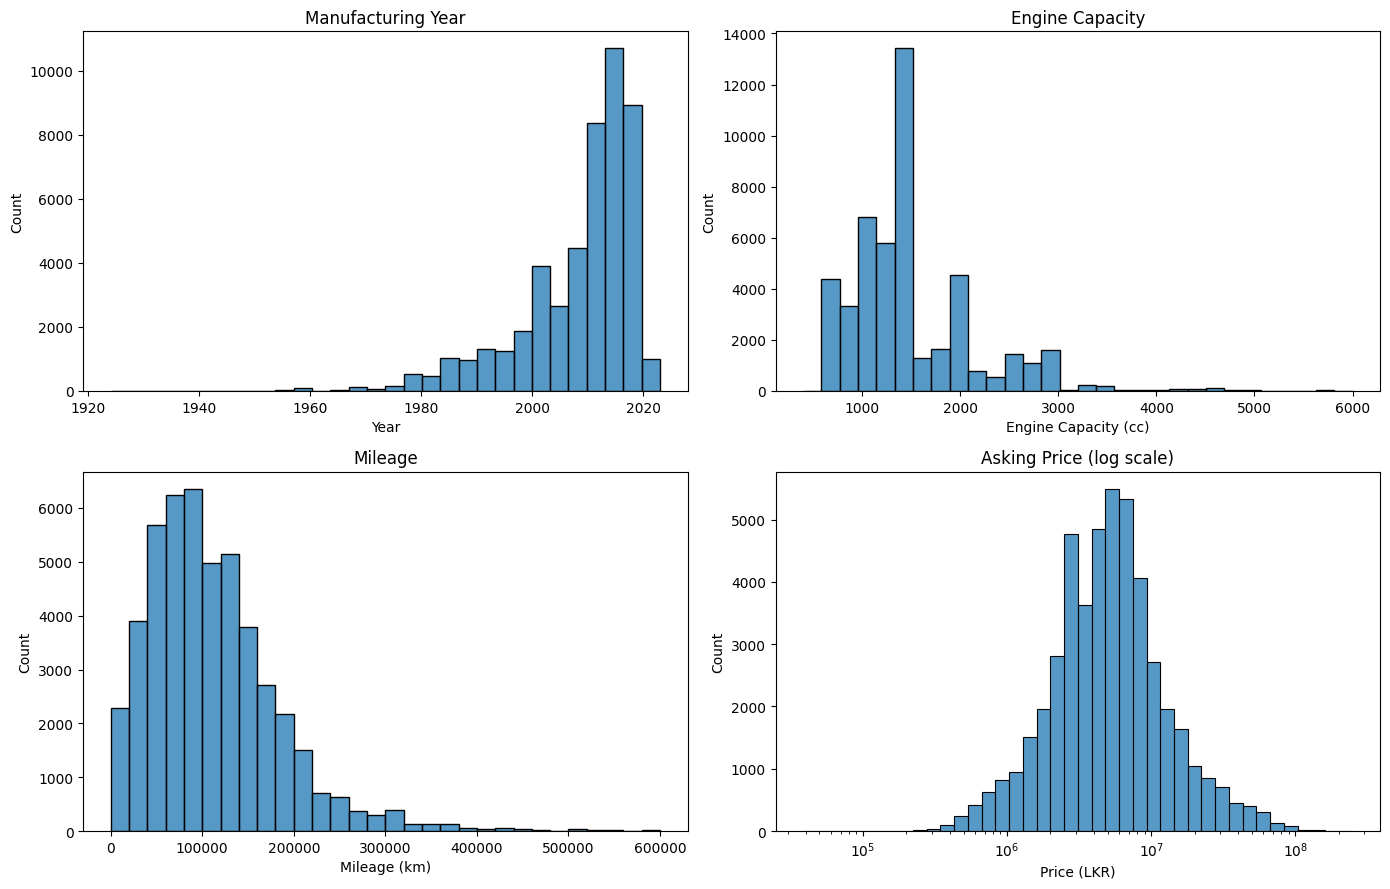

In [42]:
# visualize the distributions of the main numerical attributes

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(df1_clean["year"].dropna(), bins=30, ax=axes[0, 0])
axes[0, 0].set_title("Manufacturing Year")
axes[0, 0].set_xlabel("Year")

sns.histplot(df1_clean["engine_cc"].dropna(), bins=30, ax=axes[0, 1])
axes[0, 1].set_title("Engine Capacity")
axes[0, 1].set_xlabel("Engine Capacity (cc)")

sns.histplot(df1_clean["mileage_km"].dropna(), bins=30, ax=axes[1, 0])
axes[1, 0].set_title("Mileage")
axes[1, 0].set_xlabel("Mileage (km)")

sns.histplot(df1_clean["price_lkr"].dropna(), bins=40, log_scale=(True, False), ax=axes[1, 1])
axes[1, 1].set_title("Asking Price (log scale)")
axes[1, 1].set_xlabel("Price (LKR)")

plt.tight_layout()
plt.show()


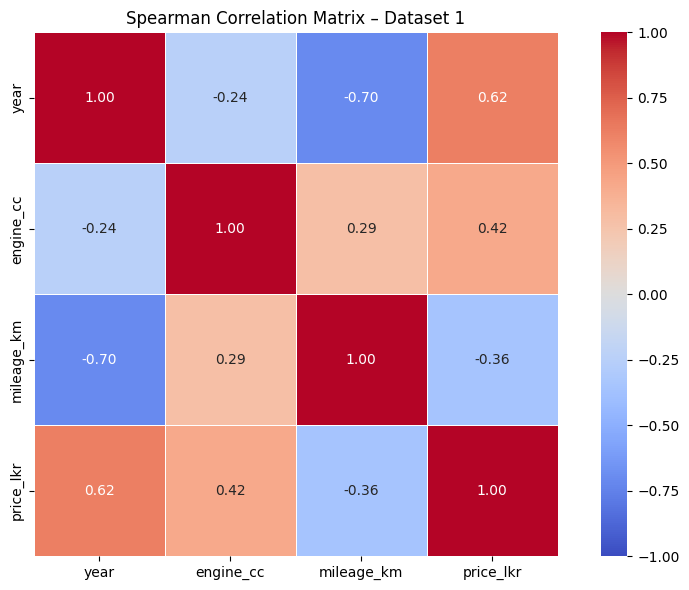

In [43]:
# calculate and visualize correlations between numerical vehicle attributes

correlation_columns = [
    "year",
    "engine_cc",
    "mileage_km",
    "price_lkr"
]

correlation_matrix = df1_clean[correlation_columns].corr(
    method="spearman"
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Spearman Correlation Matrix – Dataset 1")
plt.tight_layout()
plt.show()

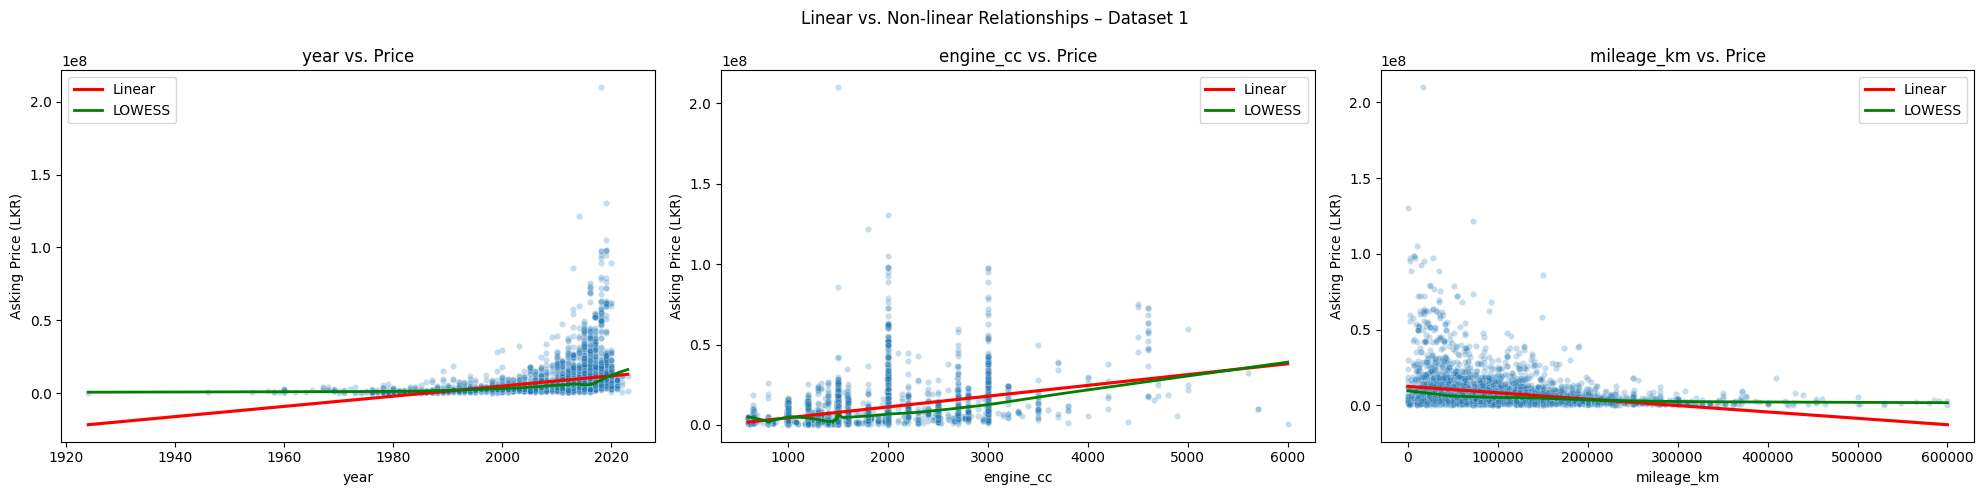

In [44]:
# compare linear and non-linear relationships in Dataset 1

import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm

plot_data = df1_clean[
    ["year", "engine_cc", "mileage_km", "price_lkr"]
].dropna()

# Use a sample for clearer and faster visualisation
plot_data = plot_data.sample(
    n=min(5000, len(plot_data)),
    random_state=42
)

features = ["year", "engine_cc", "mileage_km"]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, feature in zip(axes, features):

    sns.scatterplot(
        data=plot_data,
        x=feature,
        y="price_lkr",
        alpha=0.25,
        s=20,
        ax=ax
    )

    # Linear trend line
    sns.regplot(
        data=plot_data,
        x=feature,
        y="price_lkr",
        scatter=False,
        color="red",
        ci=None,
        ax=ax,
        label="Linear"
    )

    # LOWESS smooth curve
    lowess_result = sm.nonparametric.lowess(
        plot_data["price_lkr"],
        plot_data[feature],
        frac=0.25,
        return_sorted=True
    )

    ax.plot(
        lowess_result[:, 0],
        lowess_result[:, 1],
        color="green",
        linewidth=2,
        label="LOWESS"
    )

    ax.set_title(f"{feature} vs. Price")
    ax.set_ylabel("Asking Price (LKR)")
    ax.legend()

plt.suptitle("Linear vs. Non-linear Relationships – Dataset 1")
plt.tight_layout()
plt.show()

#### 5.1.2 Categorical attributes

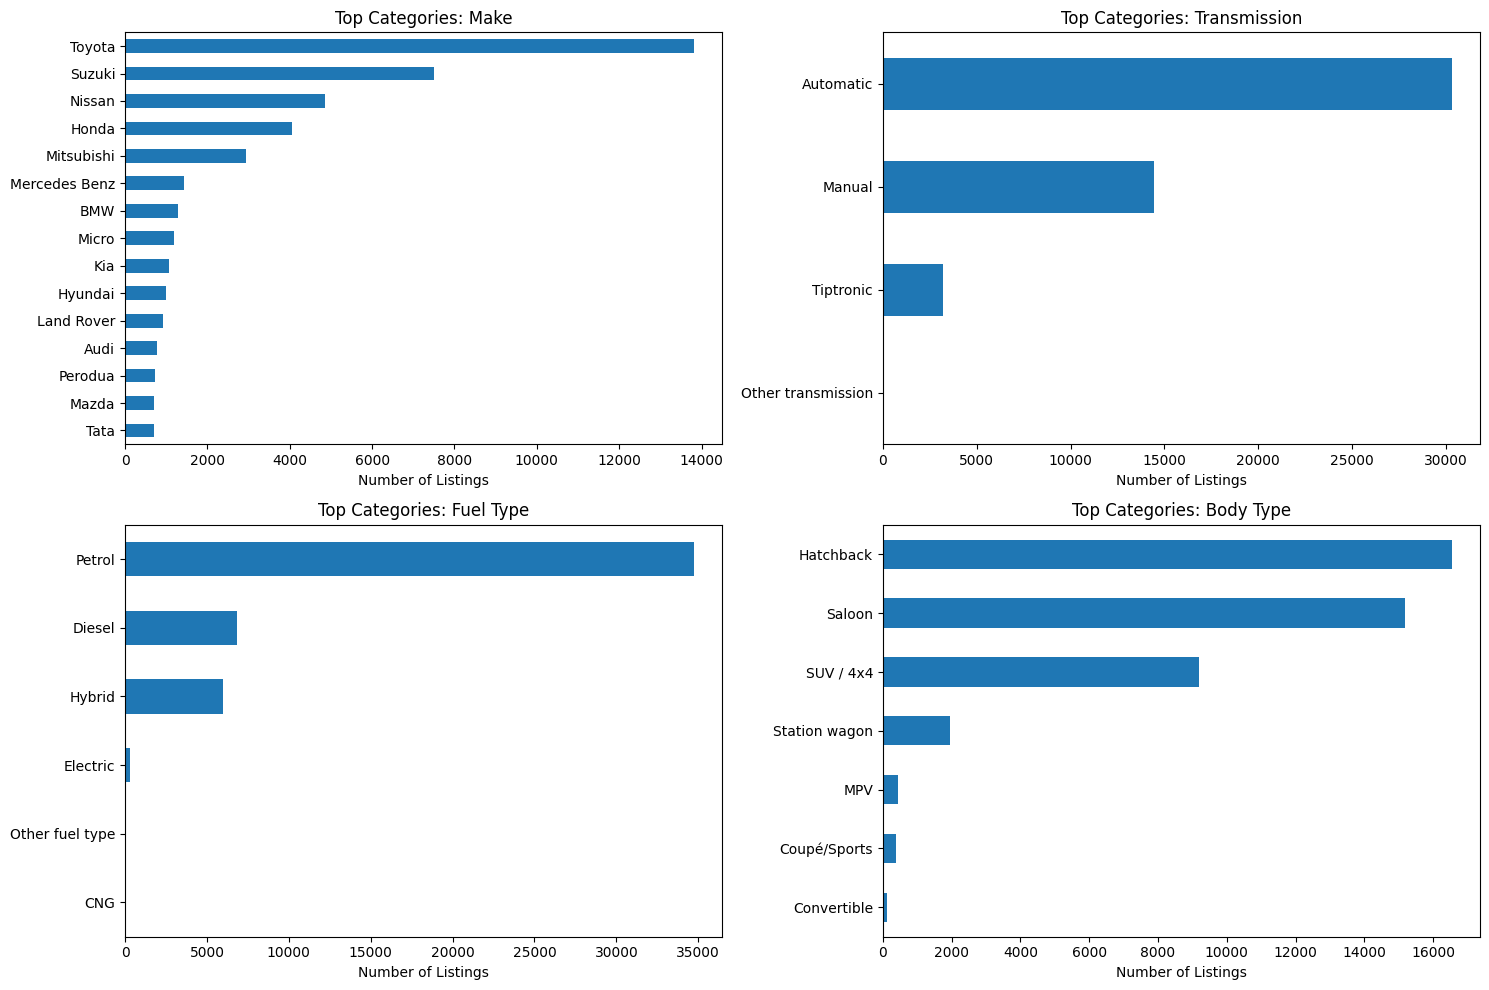

In [45]:
# visualize the most frequent categorical values

categorical_columns = ["make", "transmission", "fuel_type", "body_type"]

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

for column, ax in zip(categorical_columns, axes.flat):
    counts = df1_clean[column].value_counts().head(15).sort_values()
    counts.plot(kind="barh", ax=ax)
    ax.set_title(f"Top Categories: {column.replace('_', ' ').title()}")
    ax.set_xlabel("Number of Listings")
    ax.set_ylabel("")

plt.tight_layout()
plt.show()


### 5.2 Dataset 2

#### 5.2.1 Numerical attributes

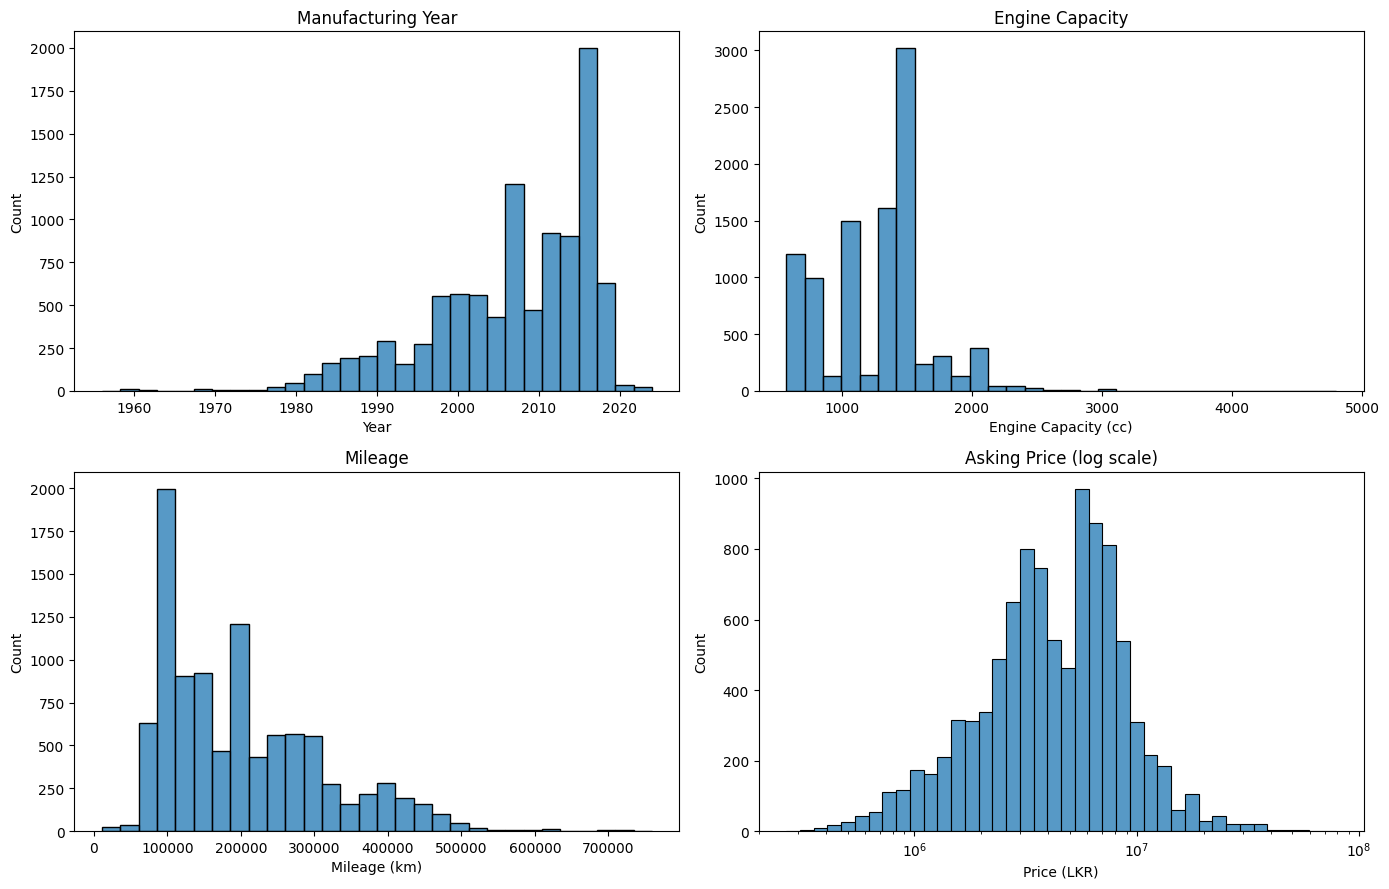

In [46]:
# visualize the distributions of the main numerical attributes

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(df2_clean["year"].dropna(), bins=30, ax=axes[0, 0])
axes[0, 0].set_title("Manufacturing Year")
axes[0, 0].set_xlabel("Year")

sns.histplot(df2_clean["engine_cc"].dropna(), bins=30, ax=axes[0, 1])
axes[0, 1].set_title("Engine Capacity")
axes[0, 1].set_xlabel("Engine Capacity (cc)")

sns.histplot(df2_clean["mileage_km"].dropna(), bins=30, ax=axes[1, 0])
axes[1, 0].set_title("Mileage")
axes[1, 0].set_xlabel("Mileage (km)")

sns.histplot(df2_clean["price_lkr"].dropna(), bins=40, log_scale=(True, False), ax=axes[1, 1])
axes[1, 1].set_title("Asking Price (log scale)")
axes[1, 1].set_xlabel("Price (LKR)")

plt.tight_layout()
plt.show()


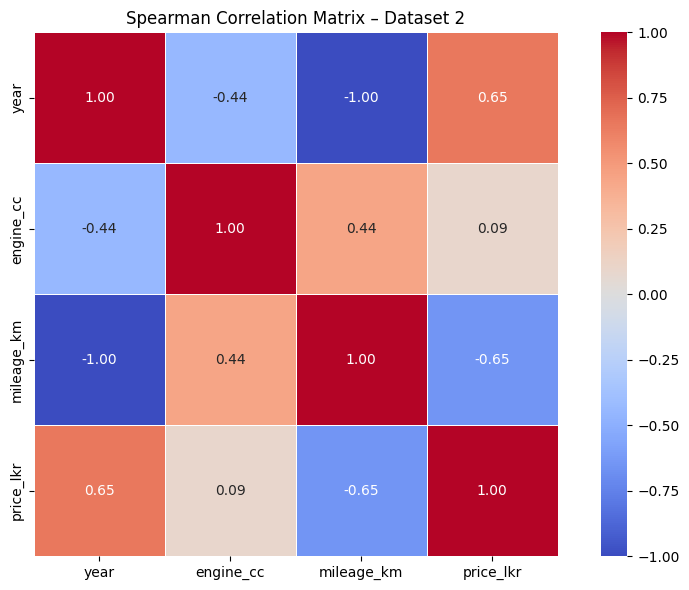

In [47]:
# calculate and visualize correlations between numerical vehicle attributes

correlation_columns = [
    "year",
    "engine_cc",
    "mileage_km",
    "price_lkr"
]

correlation_matrix = df2_clean[correlation_columns].corr(
    method="spearman"
)

plt.figure(figsize=(9, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0,
    square=True
)

plt.title("Spearman Correlation Matrix – Dataset 2")
plt.tight_layout()
plt.show()

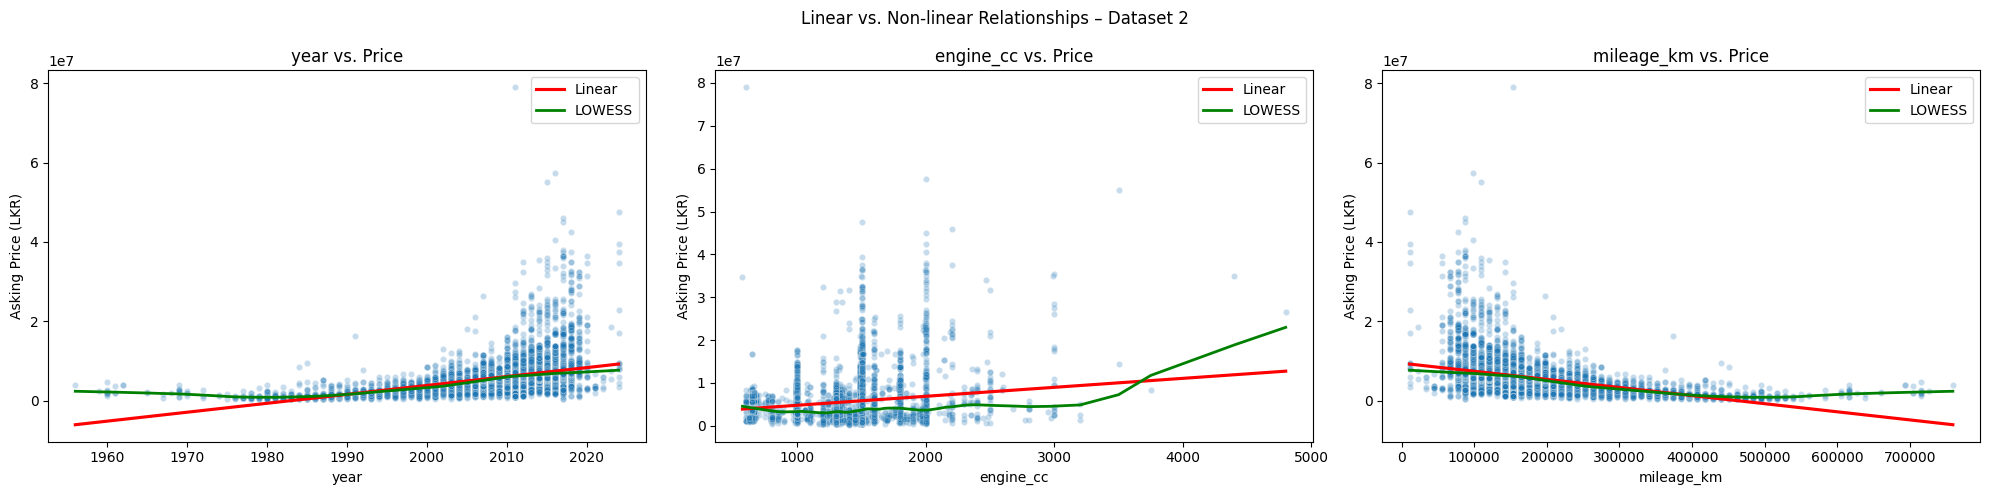

In [48]:
# compare linear and non-linear relationships in Dataset 2

plot_data = df2_clean[
    ["year", "engine_cc", "mileage_km", "price_lkr"]
].dropna()

features = ["year", "engine_cc", "mileage_km"]

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

for ax, feature in zip(axes, features):

    sns.scatterplot(
        data=plot_data,
        x=feature,
        y="price_lkr",
        alpha=0.25,
        s=20,
        ax=ax
    )

    # Linear trend line
    sns.regplot(
        data=plot_data,
        x=feature,
        y="price_lkr",
        scatter=False,
        color="red",
        ci=None,
        ax=ax,
        label="Linear"
    )

    # Aggregate repeated feature values before LOWESS smoothing
    smooth_data = (
        plot_data.groupby(feature)["price_lkr"]
        .median()
        .reset_index()
        .sort_values(feature)
    )

    lowess_result = sm.nonparametric.lowess(
        smooth_data["price_lkr"],
        smooth_data[feature],
        frac=0.25,
        return_sorted=True
    )

    ax.plot(
        lowess_result[:, 0],
        lowess_result[:, 1],
        color="green",
        linewidth=2,
        label="LOWESS"
    )

    ax.set_title(f"{feature} vs. Price")
    ax.set_ylabel("Asking Price (LKR)")
    ax.legend()

plt.suptitle("Linear vs. Non-linear Relationships – Dataset 2")
plt.tight_layout()
plt.show()

#### 5.2.2 Categorical attributes

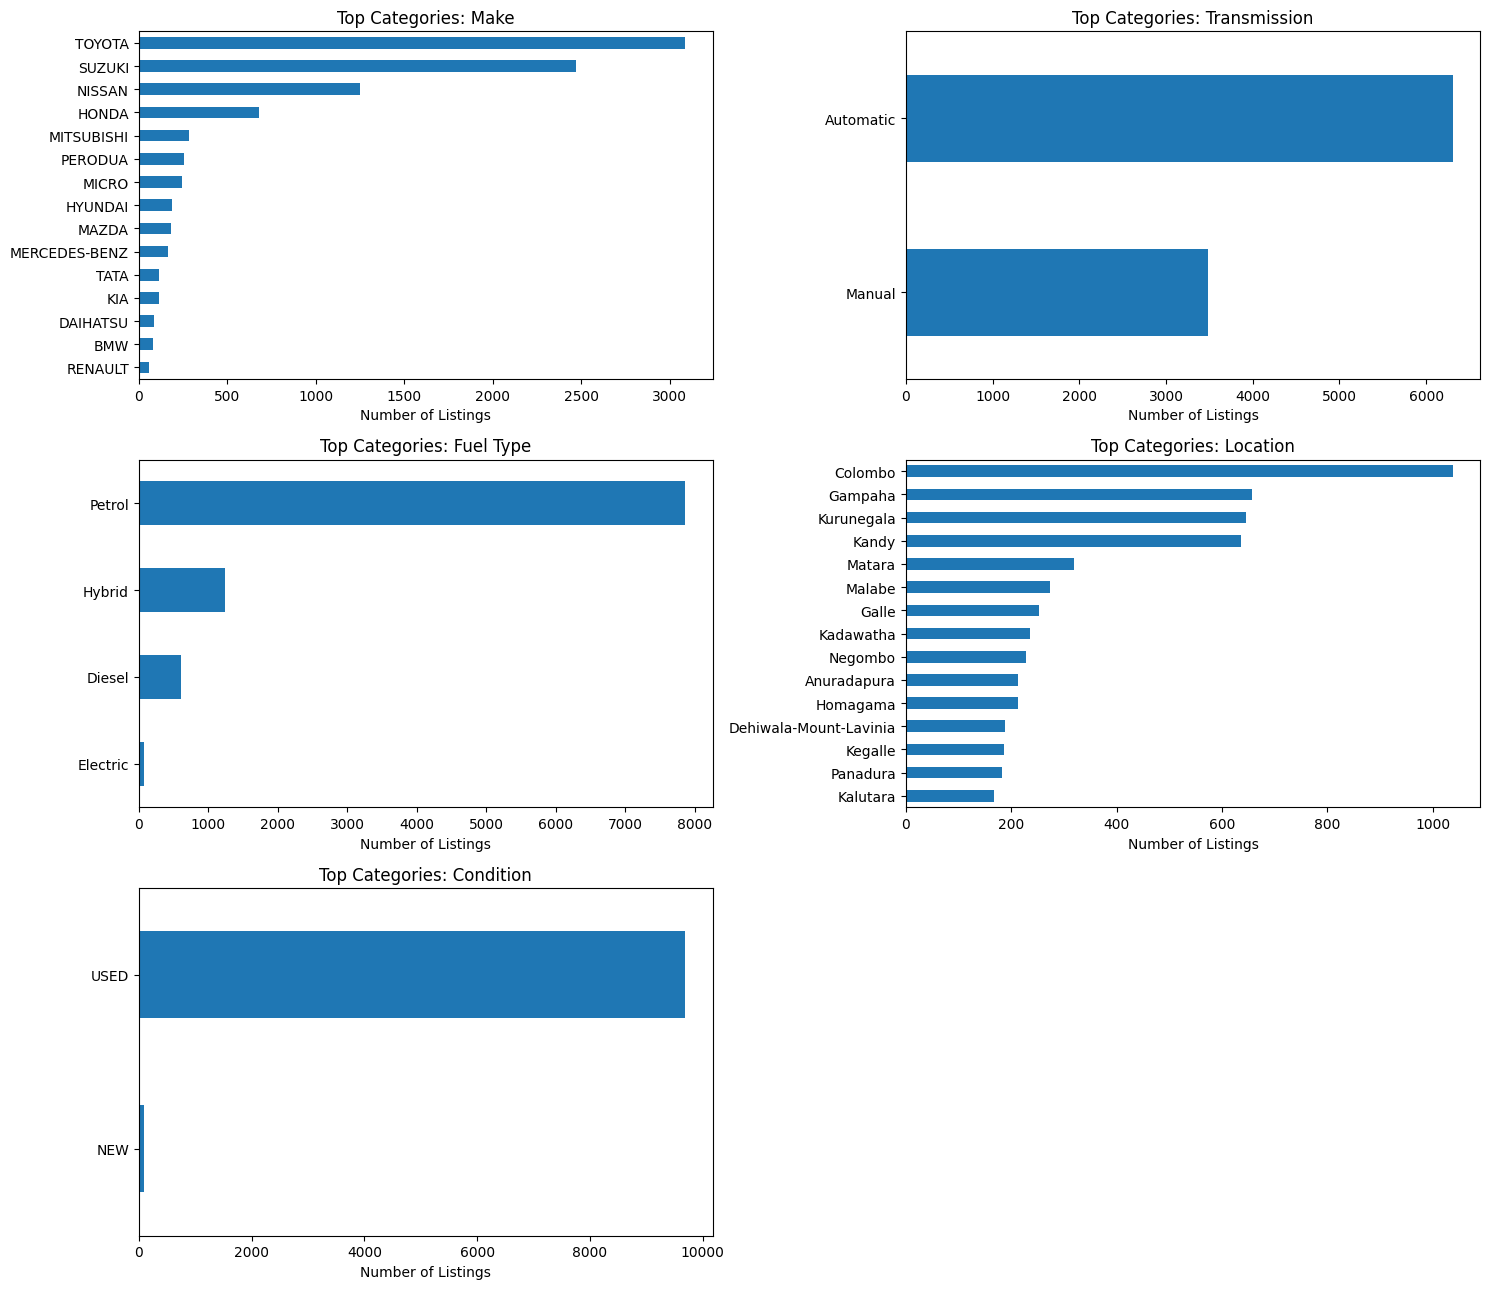

In [49]:
# visualize the most frequent categorical values

categorical_columns = [
    "make", "transmission", "fuel_type", "location", "condition"
]

fig, axes = plt.subplots(3, 2, figsize=(15, 13))

for column, ax in zip(categorical_columns, axes.flat):
    counts = df2_clean[column].value_counts().head(15).sort_values()
    counts.plot(kind="barh", ax=ax)
    ax.set_title(f"Top Categories: {column.replace('_', ' ').title()}")
    ax.set_xlabel("Number of Listings")
    ax.set_ylabel("")

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()
